# **TOPIC:** IMPROVING CHURN PREDICTION IN THE TELECOMMUNICATION INDUSTRY USING MACHINE LEARNING

# **Dataset: Cell2Cell**

The Cell2Cell dataset is an open-source telecommunications customer churn dataset created by the Teradata Center for Customer Relationship Management at Duke University for a 2003 churn modeling tournament.

Source: https://www.kaggle.com/datasets/geoamins/cell2cell-duke-university-telco-dataset

# **PHASE 3** & **PHASE 4**

# PHASE 3: Data Cleaning, Explanatory Data Analysis and Feature Enineering


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

dataset_path = '/content/drive/MyDrive/437/project_dataset/'

if os.path.exists(dataset_path):
    print(f"Contents of {dataset_path}:")
    for item in os.listdir(dataset_path):
        print(item)
else:
    print(f"The folder '{dataset_path}' does not exist.")

Contents of /content/drive/MyDrive/437/project_dataset/:
cell2cellholdout.csv
cell2celltrain.csv
X_train_processed.csv
X_holdout_processed.csv
X_train_processed.gsheet
y_train_processed.csv
y_holdout_processed.csv
X_processed.csv
y_processed.csv


In [ ]:
import pandas as pd

dataset_path = '/content/drive/MyDrive/437/project_dataset/'

train_df = pd.read_csv(f'{dataset_path}cell2celltrain.csv')

## Initial Exploratory Data Analysis (EDA)

A general overview of the dataframes, including descriptive statistics, information about column types, and an initial assessment of missing values before proceeding with the feature engineering.

In [ ]:
print("### Train DataFrame Info ###")
display(train_df.info())

### Train DataFrame Info ###
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51047 entries, 0 to 51046
Data columns (total 58 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CustomerID                 51047 non-null  int64  
 1   Churn                      51047 non-null  object 
 2   MonthlyRevenue             50891 non-null  float64
 3   MonthlyMinutes             50891 non-null  float64
 4   TotalRecurringCharge       50891 non-null  float64
 5   DirectorAssistedCalls      50891 non-null  float64
 6   OverageMinutes             50891 non-null  float64
 7   RoamingCalls               50891 non-null  float64
 8   PercChangeMinutes          50680 non-null  float64
 9   PercChangeRevenues         50680 non-null  float64
 10  DroppedCalls               51047 non-null  float64
 11  BlockedCalls               51047 non-null  float64
 12  UnansweredCalls            51047 non-null  float64
 13  CustomerCareCalls

None

### Descriptive Statistics for Numerical Columns

This provides a statistical summary of the numerical features, including count, mean, standard deviation, min, max, and quartile values. This can highlight potential outliers, skewness, and the range of data.

In [ ]:
print("### Train DataFrame Numerical Descriptive Statistics ###")
display(train_df.describe())

### Train DataFrame Numerical Descriptive Statistics ###


,CustomerID,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,...,Handsets,HandsetModels,CurrentEquipmentDays,AgeHH1,AgeHH2,RetentionCalls,RetentionOffersAccepted,ReferralsMadeBySubscriber,IncomeGroup,AdjustmentsToCreditRating
count,5.104700e+04,50891.000000,50891.000000,50891.000000,50891.000000,50891.000000,50891.000000,50680.000000,50680.000000,51047.000000,...,51046.000000,51046.000000,51046.000000,50138.000000,50138.000000,51047.000000,51047.000000,51047.000000,51047.000000,51047.000000
mean,3.201957e+06,58.834492,525.653416,46.830088,0.895229,40.027785,1.236244,-11.547908,-1.191985,6.011489,...,1.805646,1.558751,380.545841,31.338127,21.144142,0.037201,0.018277,0.052070,4.324524,0.053911
std,1.169056e+05,44.507336,529.871063,23.848871,2.228546,96.588076,9.818294,257.514772,39.574915,9.043955,...,1.331173,0.905932,253.801982,22.094635,23.931368,0.206483,0.142458,0.307592,3.138236,0.383147
min,3.000002e+06,-6.170000,0.000000,-11.000000,0.000000,0.000000,0.000000,-3875.000000,-1107.700000,0.000000,...,1.000000,1.000000,-5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.100632e+06,33.610000,158.000000,30.000000,0.000000,0.000000,0.000000,-83.000000,-7.100000,0.700000,...,1.000000,1.000000,205.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.201534e+06,48.460000,366.000000,45.000000,0.250000,3.000000,0.000000,-5.000000,-0.300000,3.000000,...,1.000000,1.000000,329.000000,36.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.000000
75%,3.305376e+06,71.065000,723.000000,60.000000,0.990000,41.000000,0.300000,66.000000,1.600000,7.700000,...,2.000000,2.000000,515.000000,48.000000,42.000000,0.000000,0.000000,0.000000,7.000000,0.000000
max,3.399994e+06,1223.380000,7359.000000,400.000000,159.390000,4321.000000,1112.400000,5192.000000,2483.500000,221.700000,...,24.000000,15.000000,1812.000000,99.000000,99.000000,4.000000,3.000000,35.000000,9.000000,25.000000


### Non-Numeric Columns


In [ ]:
import numpy as np

print("### Train DataFrame Non-Numeric Columns ###")
non_numeric_cols_train = train_df.select_dtypes(exclude=np.number).columns
print(f"Non-numeric columns in train_df: {list(non_numeric_cols_train)}")

### Train DataFrame Non-Numeric Columns ###
Non-numeric columns in train_df: ['Churn', 'ServiceArea', 'ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner', 'Homeownership', 'BuysViaMailOrder', 'RespondsToMailOffers', 'OptOutMailings', 'NonUSTravel', 'OwnsComputer', 'HasCreditCard', 'NewCellphoneUser', 'NotNewCellphoneUser', 'OwnsMotorcycle', 'HandsetPrice', 'MadeCallToRetentionTeam', 'CreditRating', 'PrizmCode', 'Occupation', 'MaritalStatus']


### Initial Missing Value Analysis

This section provides a visual representation and counts of missing values across both datasets before any imputation. This clearly shows which columns have missing data and to what extent.

/tmp/ipykernel_699/3062895030.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_counts.index, y=missing_counts.values, palette='viridis')


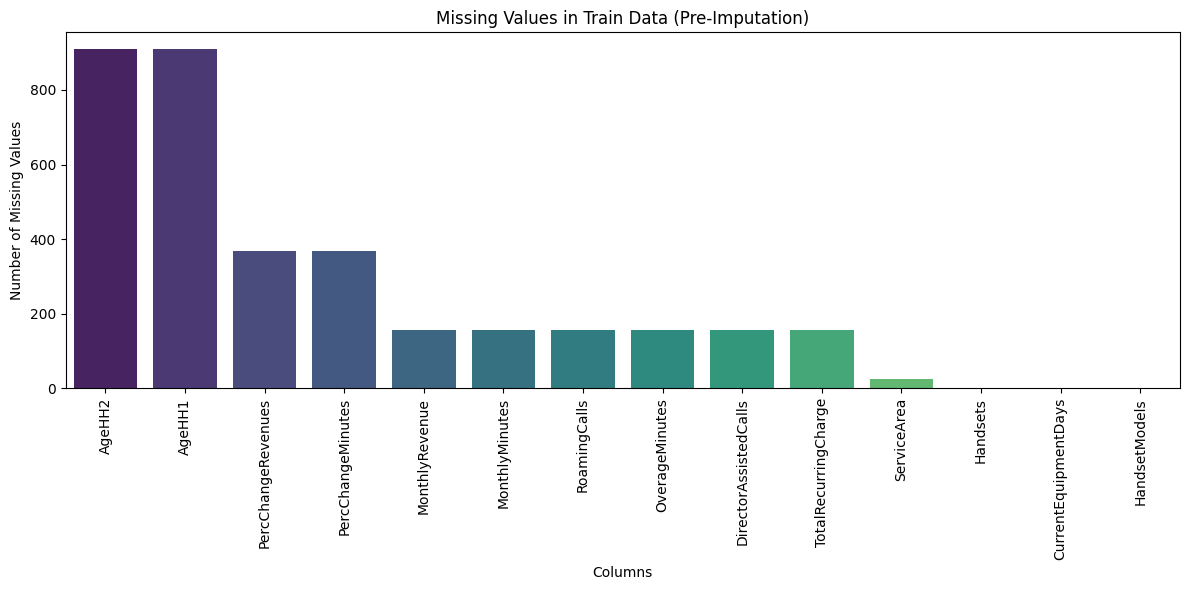

Missing values in Train Data:
AgeHH2                   909
AgeHH1                   909
PercChangeRevenues       367
PercChangeMinutes        367
MonthlyRevenue           156
MonthlyMinutes           156
RoamingCalls             156
OverageMinutes           156
DirectorAssistedCalls    156
TotalRecurringCharge     156
ServiceArea               24
Handsets                   1
CurrentEquipmentDays       1
HandsetModels              1
dtype: int64



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_missing_values(df, title):
    missing_counts = df.isnull().sum()
    missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

    if not missing_counts.empty:
        plt.figure(figsize=(12, 6))
        sns.barplot(x=missing_counts.index, y=missing_counts.values, palette='viridis')
        plt.title(f'Missing Values in {title} (Pre-Imputation)')
        plt.xlabel('Columns')
        plt.ylabel('Number of Missing Values')
        plt.xticks(rotation=90)
        plt.tight_layout()
        plt.show()
        print(f"Missing values in {title}:\n{missing_counts}\n")
    else:
        print(f"No missing values found in {title}.\n")

plot_missing_values(train_df, 'Train Data')

---

## Unique Values and Percentages in Categorical Columns

we analyzed the unique values and their percentages for categorical columns in both the training and holdout datasets.


In [ ]:
def analyze_categorical_columns(df, df_name):
    print(f"Categorical Feature Analysis for {df_name}")
    categorical_cols = df.select_dtypes(include='object').columns.tolist()

    # Exclude 'CustomerID' and 'Churn' (if present and categorical) as they are not features for this analysis
    if 'CustomerID' in categorical_cols:
        categorical_cols.remove('CustomerID')
    if 'Churn' in categorical_cols:
        categorical_cols.remove('Churn')

    if not categorical_cols:
        print("No categorical columns found for analysis.")
        return

    for col in categorical_cols:
        print(f"\nColumn: {col}")
        value_counts = df[col].value_counts(dropna=False) # Include NaN counts
        percentages = df[col].value_counts(dropna=False, normalize=True) * 100
        combined_info = pd.DataFrame({'Count': value_counts, 'Percentage': percentages.round(2).astype(str) + '%'}) # Format percentages
        display(combined_info)

analyze_categorical_columns(train_df, 'Train Data')

Categorical Feature Analysis for Train Data

Column: ServiceArea


,Count,Percentage
ServiceArea,,
NYCBRO917,1684,3.3%
HOUHOU281,1510,2.96%
DALDAL214,1498,2.93%
NYCMAN917,1182,2.32%
APCFCH703,783,1.53%
...,...,...
SFRRCM510,1,0.0%
INHKOK765,1,0.0%
NOLPOH504,1,0.0%



Column: ChildrenInHH


,Count,Percentage
ChildrenInHH,,
No,38679,75.77%
Yes,12368,24.23%



Column: HandsetRefurbished


,Count,Percentage
HandsetRefurbished,,
No,43956,86.11%
Yes,7091,13.89%


... (34 outputs left out)


Column: Occupation


,Count,Percentage
Occupation,,
Other,37637,73.73%
Professional,8755,17.15%
Crafts,1519,2.98%
Clerical,986,1.93%
Self,879,1.72%
Retired,733,1.44%
Student,381,0.75%
Homemaker,157,0.31%



Column: MaritalStatus


,Count,Percentage
MaritalStatus,,
Unknown,19700,38.59%
Yes,18651,36.54%
No,12696,24.87%


## Numerical and Categorical Columns (Initial Identification)

In [ ]:
# Identify numerical columns
numerical_cols_initial = train_df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Identify categorical columns (excluding 'CustomerID' and 'Churn')
categorical_cols_initial = train_df.select_dtypes(include='object').columns.tolist()
if 'CustomerID' in categorical_cols_initial:
    categorical_cols_initial.remove('CustomerID')
if 'Churn' in categorical_cols_initial:
    categorical_cols_initial.remove('Churn')

print(f"Initial Numerical Columns ({len(numerical_cols_initial)}):\n{numerical_cols_initial}")
print(f"\nInitial Categorical Columns ({len(categorical_cols_initial)}):\n{categorical_cols_initial}")

Initial Numerical Columns (35):
['CustomerID', 'MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues', 'DroppedCalls', 'BlockedCalls', 'UnansweredCalls', 'CustomerCareCalls', 'ThreewayCalls', 'ReceivedCalls', 'OutboundCalls', 'InboundCalls', 'PeakCallsInOut', 'OffPeakCallsInOut', 'DroppedBlockedCalls', 'CallForwardingCalls', 'CallWaitingCalls', 'MonthsInService', 'UniqueSubs', 'ActiveSubs', 'Handsets', 'HandsetModels', 'CurrentEquipmentDays', 'AgeHH1', 'AgeHH2', 'RetentionCalls', 'RetentionOffersAccepted', 'ReferralsMadeBySubscriber', 'IncomeGroup', 'AdjustmentsToCreditRating']

Initial Categorical Columns (22):
['ServiceArea', 'ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner', 'Homeownership', 'BuysViaMailOrder', 'RespondsToMailOffers', 'OptOutMailings', 'NonUSTravel', 'OwnsComputer', 'HasCreditCard', 'NewCellphoneUser', 'NotNewCellphoneUser', 'Own

## Initial EDA Visualizations

### Distributions of Initial Numerical Features

Distributions of the initially identified numerical features using histograms to understand their spread and detect potential issues like skewness or multimodal distributions.

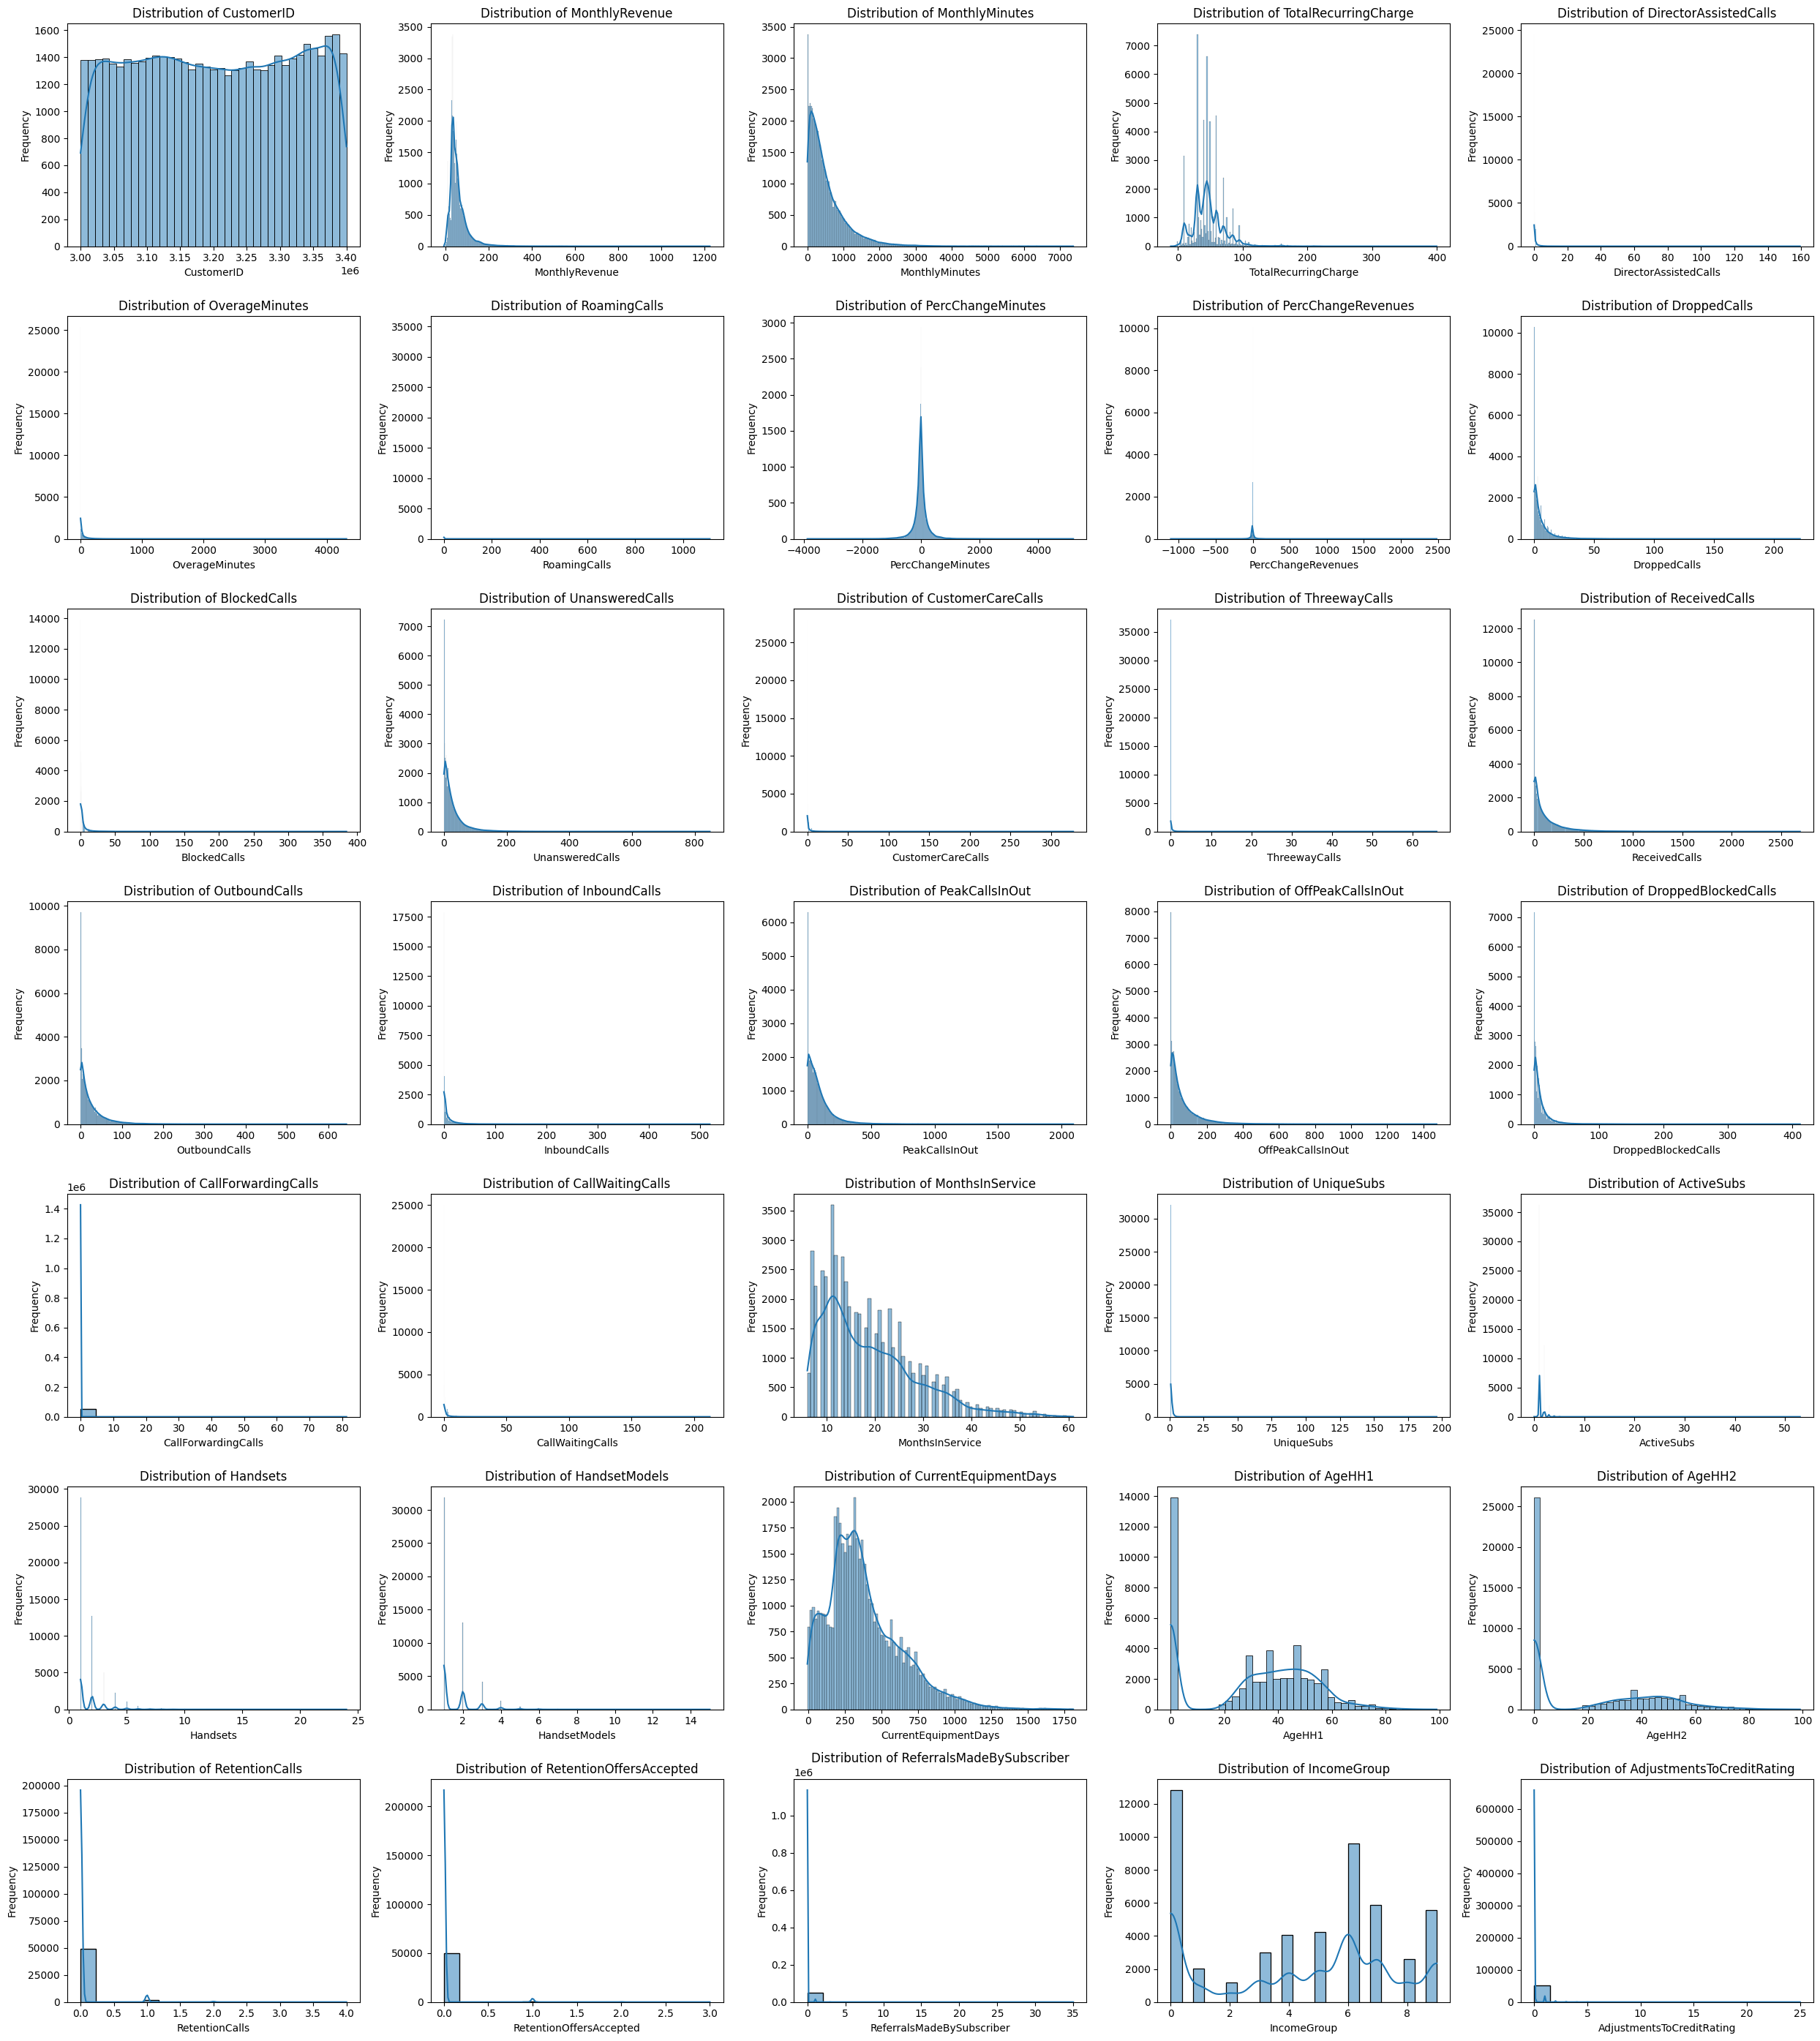

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select a few representative numerical columns for visualization
numerical_cols_to_plot = ['CustomerID', 'MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues', 'DroppedCalls', 'BlockedCalls', 'UnansweredCalls', 'CustomerCareCalls', 'ThreewayCalls', 'ReceivedCalls', 'OutboundCalls', 'InboundCalls', 'PeakCallsInOut', 'OffPeakCallsInOut', 'DroppedBlockedCalls', 'CallForwardingCalls', 'CallWaitingCalls', 'MonthsInService', 'UniqueSubs', 'ActiveSubs', 'Handsets', 'HandsetModels', 'CurrentEquipmentDays', 'AgeHH1', 'AgeHH2', 'RetentionCalls', 'RetentionOffersAccepted', 'ReferralsMadeBySubscriber', 'IncomeGroup', 'AdjustmentsToCreditRating']

# Ensure selected columns exist in the DataFrame
numerical_cols_to_plot = [col for col in numerical_cols_to_plot if col in train_df.columns]

if numerical_cols_to_plot:
    n_plots = len(numerical_cols_to_plot)
    n_cols = 5
    n_rows = (n_plots + n_cols - 1) // n_cols # Calculate rows needed

    plt.figure(figsize=(n_cols * 5, n_rows * 4))
    for i, col in enumerate(numerical_cols_to_plot, 1):
        plt.subplot(n_rows, n_cols, i)
        sns.histplot(train_df[col].dropna(), kde=True)
        plt.title(f'Distribution of {col}')
        plt.xlabel(col)
        plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()
else:
    print("No numerical columns found for plotting.")

### Distributions of Initial Categorical Features

Examined the distributions of some of the initially identified categorical features using count plots. This helps us understand the frequency of each category before any encoding or cardinality reduction.

/tmp/ipykernel_699/978204707.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=train_df[col], order=train_df[col].value_counts().index, palette='viridis')
/tmp/ipykernel_699/978204707.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=train_df[col], order=train_df[col].value_counts().index, palette='viridis')
/tmp/ipykernel_699/978204707.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=train_df[col], order=train_df[col].value_counts().index, palette='viridis')
/tmp/ipykernel_699/978204707.py:18: FutureWarning: 

Passing 

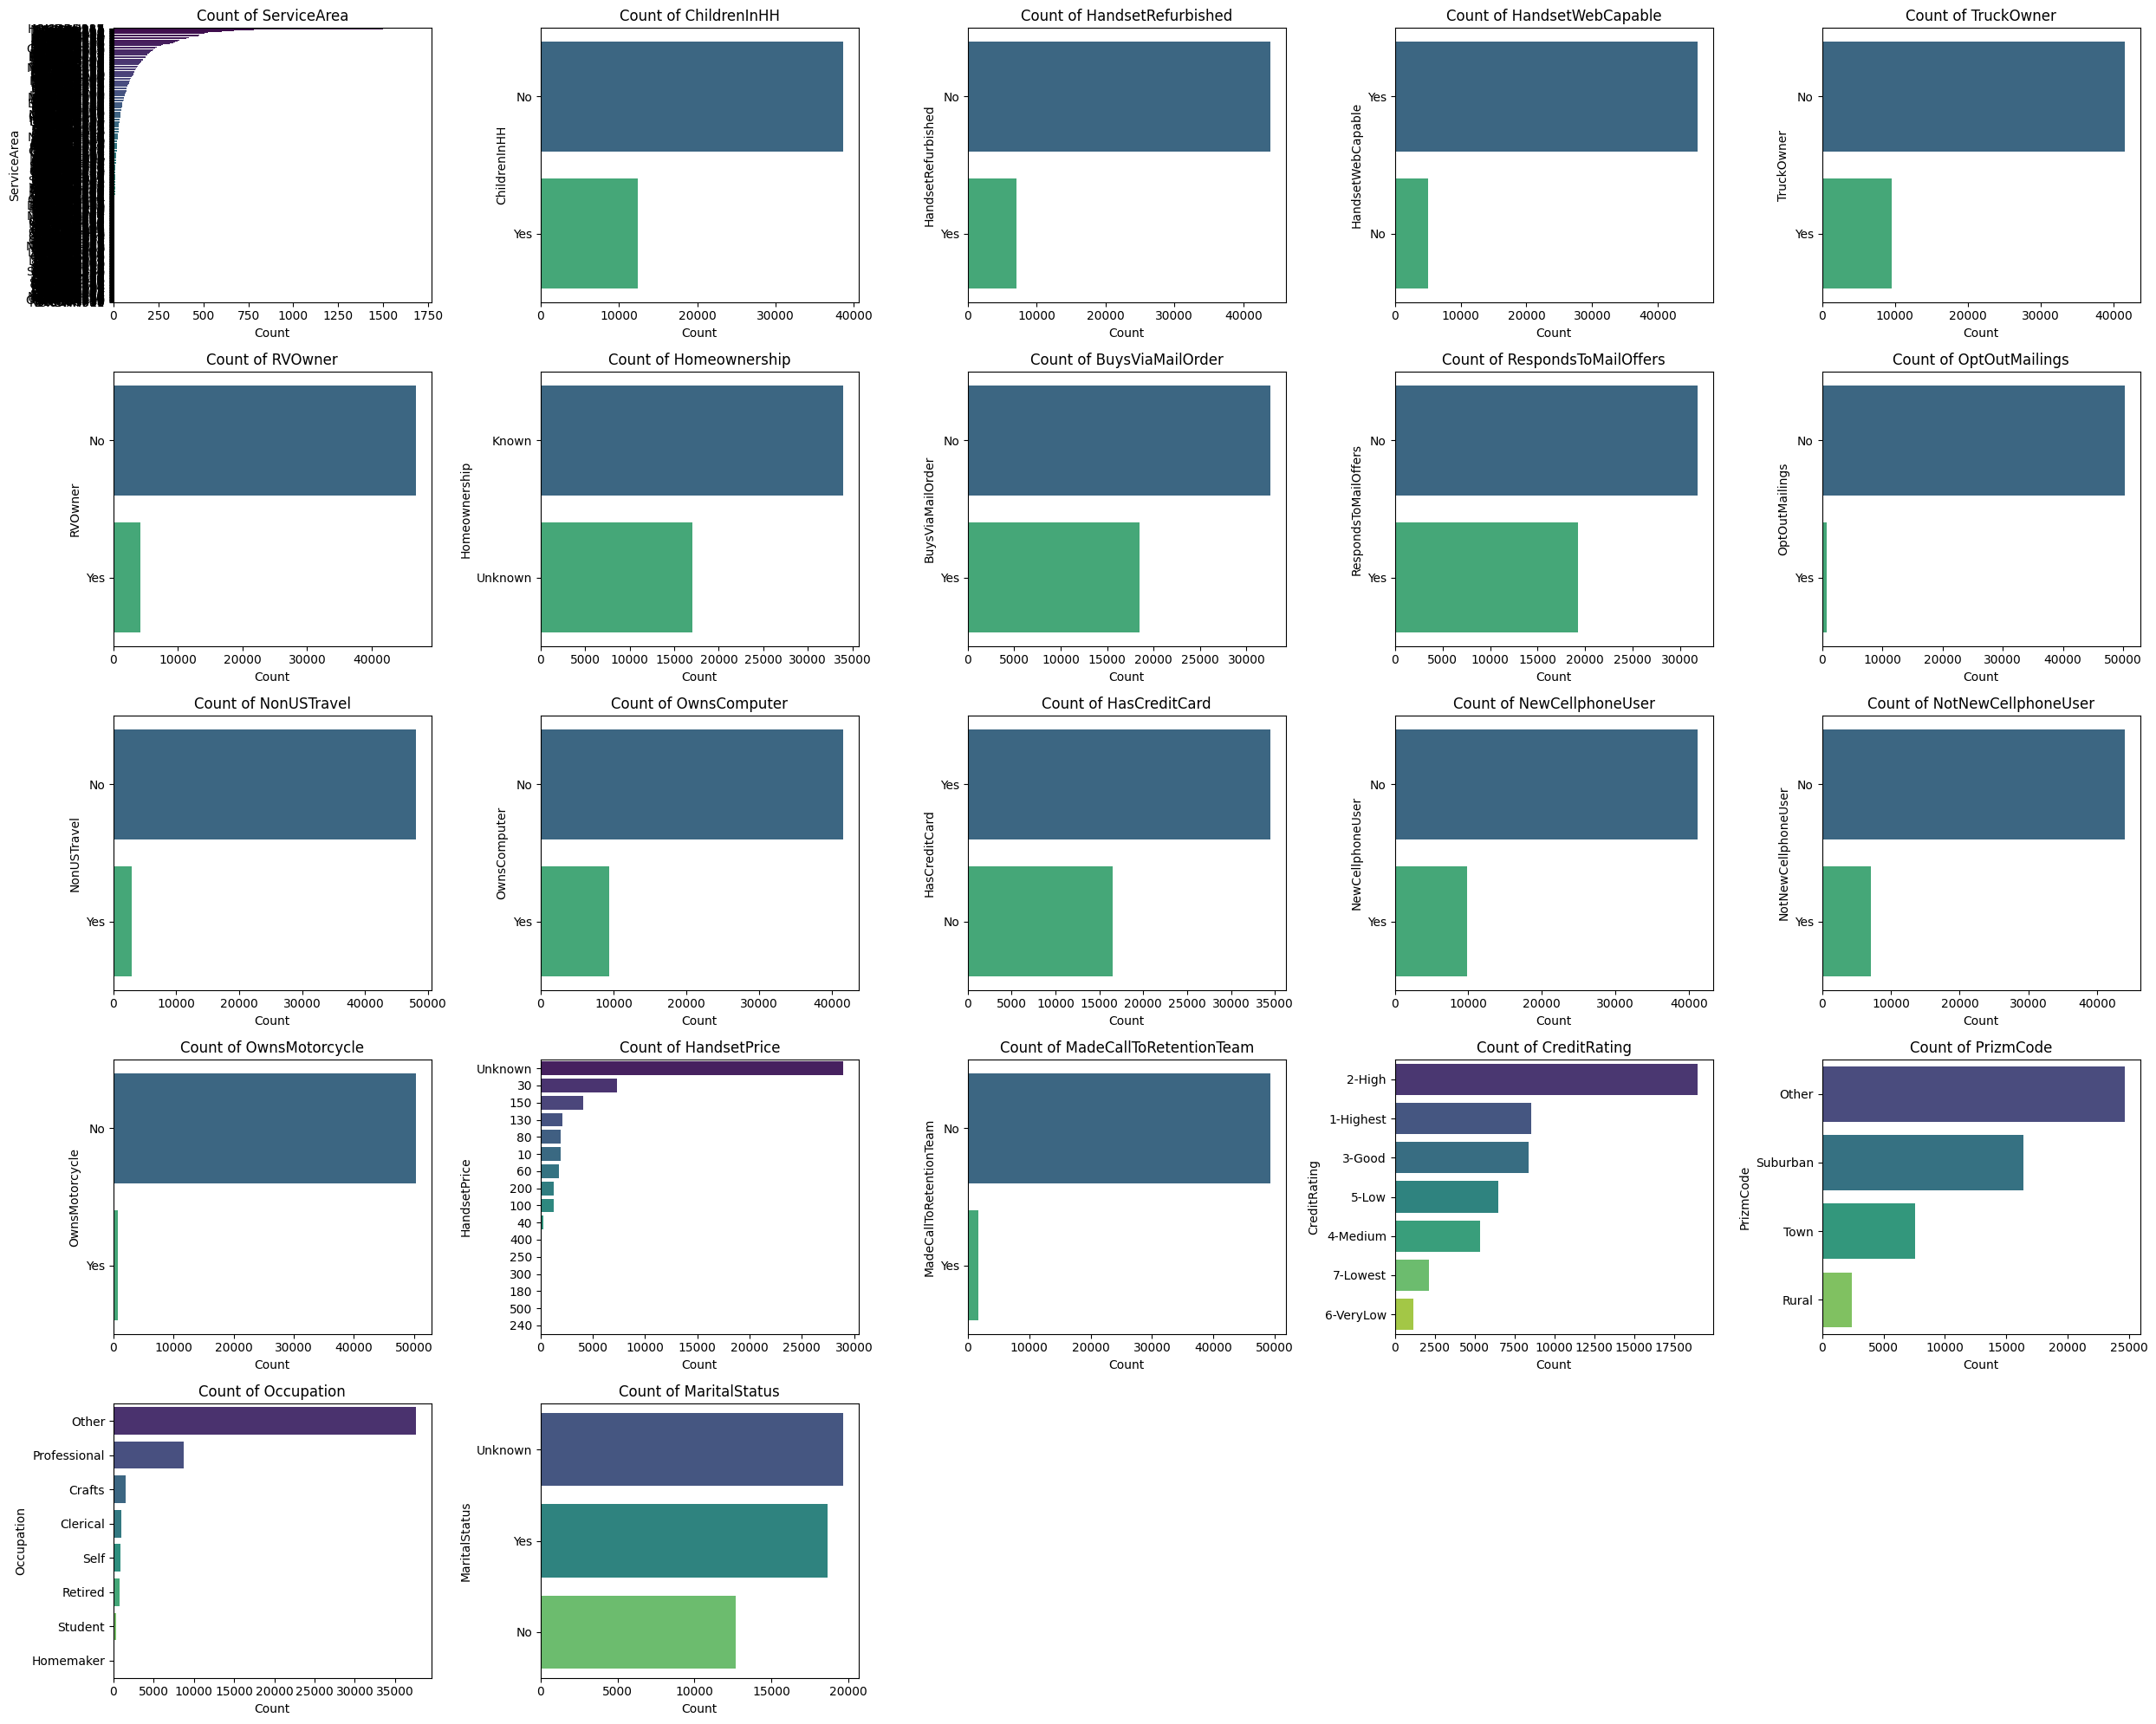

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select a few representative categorical columns for visualization
categorical_cols_to_plot = ['ServiceArea', 'ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner', 'Homeownership', 'BuysViaMailOrder', 'RespondsToMailOffers', 'OptOutMailings', 'NonUSTravel', 'OwnsComputer', 'HasCreditCard', 'NewCellphoneUser', 'NotNewCellphoneUser', 'OwnsMotorcycle', 'HandsetPrice', 'MadeCallToRetentionTeam', 'CreditRating', 'PrizmCode', 'Occupation', 'MaritalStatus']

# Ensure selected columns exist in the DataFrame
categorical_cols_to_plot = [col for col in categorical_cols_to_plot if col in train_df.columns]

if categorical_cols_to_plot:
    n_plots = len(categorical_cols_to_plot)
    n_cols = 5
    n_rows = (n_plots + n_cols - 1) // n_cols # Calculate rows needed

    plt.figure(figsize=(n_cols * 5, n_rows * 4))
    for i, col in enumerate(categorical_cols_to_plot, 1):
        plt.subplot(n_rows, n_cols, i)
        sns.countplot(y=train_df[col], order=train_df[col].value_counts().index, palette='viridis')
        plt.title(f'Count of {col}')
        plt.xlabel('Count')
        plt.ylabel(col)
    plt.tight_layout()
    plt.show()
else:
    print("No categorical columns found for plotting.")

## Feature Engineering Workflow

### Step 1: Baseline Data Split

We separate the target variable 'Churn' from the features for both the training and holdout datasets. For the holdout set, 'Churn' is expected to be null as it's the prediction target.

In [ ]:
import numpy as np

# Separate target variable (Churn) from features for the full dataset
X_features = train_df.drop('Churn', axis=1)
y_target = train_df['Churn']

print(f"Shape of X_features: {X_features.shape}")
print(f"Shape of y_target: {y_target.shape}")

Shape of X_features: (51047, 57)
Shape of y_target: (51047,)


### Step 2: Outlier Trimming and Capping

We identify numerical features with outliers and apply a capping strategy. Outliers are determined using the 99th percentile for upper bounds. The capping thresholds are learned only from the training data X_train to prevent data leakage and then applied to both X_train and X_holdout.

In [ ]:
numerical_cols = X_features.select_dtypes(include=np.number).columns.tolist()

# Exclude 'CustomerID' from numerical columns for outlier capping
if 'CustomerID' in numerical_cols:
    numerical_cols.remove('CustomerID')

capping_thresholds = {}
for col in numerical_cols:
    upper_bound = X_features[col].quantile(0.99)
    capping_thresholds[col] = upper_bound

# Apply capping to X_features
for col in numerical_cols:
    X_features[col] = np.where(X_features[col] > capping_thresholds[col],
                            capping_thresholds[col],
                            X_features[col])

print("Outlier capping applied to numerical columns based on X_features percentiles.")

Outlier capping applied to numerical columns based on X_features percentiles.


### Step 3: Missing Data Imputation

Missing values are handled using different imputation strategies based on the feature type:
- **HandsetPrice** is converted to numeric and then imputed.
- **Demographic Numerical Features**: Imputed using KNNImputer.
- **Other Numerical Features**: Imputed using the median.
- **Categorical Features**: Imputed using the mode.

All imputation parameters are learned solely from the training data X_train to avoid data leakage and then applied to both X_train and X_holdout.

In [ ]:
from sklearn.impute import KNNImputer, SimpleImputer

# Convert 'HandsetPrice' to numeric, coercing errors to NaN
X_features['HandsetPrice'] = pd.to_numeric(X_features['HandsetPrice'], errors='coerce')

# Define column types
demographic_numerical_cols = ['AgeHH1', 'AgeHH2', 'IncomeGroup']
other_numerical_cols = X_features.select_dtypes(include=np.number).columns.tolist()

# Remove 'CustomerID' and demographic columns from other_numerical_cols
if 'CustomerID' in other_numerical_cols:
    other_numerical_cols.remove('CustomerID')
for col in demographic_numerical_cols:
    if col in other_numerical_cols:
        other_numerical_cols.remove(col)

categorical_cols = X_features.select_dtypes(include='object').columns.tolist()
# Remove 'CustomerID' from categorical columns
if 'CustomerID' in categorical_cols:
    categorical_cols.remove('CustomerID')

# Imputation for demographic numerical features using KNNImputer
knn_imputer = KNNImputer(n_neighbors=5)
X_features[demographic_numerical_cols] = knn_imputer.fit_transform(X_features[demographic_numerical_cols])

# Imputation for other numerical features using MedianImputer
median_imputer = SimpleImputer(strategy='median')
X_features[other_numerical_cols] = median_imputer.fit_transform(X_features[other_numerical_cols])

# Imputation for categorical features using ModeImputer
mode_imputer = SimpleImputer(strategy='most_frequent')
X_features[categorical_cols] = mode_imputer.fit_transform(X_features[categorical_cols])

print("Missing values imputed for all relevant columns.")
print(f"Missing values in X_features after imputation: {X_features.isnull().sum().sum()}")

Missing values imputed for all relevant columns.
Missing values in X_features after imputation: 0


### Step 3.1: Duplicate Handling

Checking for and remove any duplicate rows in our feature sets X_train and X_holdout to prevent our model from learning redundant information or being biased by repeated samples. We will also ensure that the corresponding target values in `y_train` are removed.

In [ ]:
print(f"Initial shape of X_features: {X_features.shape}")
print(f"Initial shape of y_target: {y_target.shape}")

# Find duplicate rows in X_features based on all columns (excluding CustomerID for now)
duplicates_features = X_features.drop(columns=['CustomerID']).duplicated()
print(f"Number of duplicate rows found in X_features: {duplicates_features.sum()}")

Initial shape of X_features: (51047, 57)
Initial shape of y_target: (51047,)
Number of duplicate rows found in X_features: 0


In [ ]:
# Remove duplicate rows from X_features and y_target
# We drop duplicates from X_features and use its index to filter y_target
X_features_no_duplicates = X_features.drop_duplicates(subset=X_features.columns.drop('CustomerID'))
y_target_no_duplicates = y_target.loc[X_features_no_duplicates.index]

# Update X_features and y_target
X_features = X_features_no_duplicates
y_target = y_target_no_duplicates

print(f"Shape of X_features after removing duplicates: {X_features.shape}")
print(f"Shape of y_target after removing duplicates: {y_target.shape}")

Shape of X_features after removing duplicates: (51047, 57)
Shape of y_target after removing duplicates: (51047,)


### Step 3.2: Cardinality Reduction for 'ServiceArea'

Before proceeding with full categorical encoding, we address the high cardinality of the 'ServiceArea' feature. Categories that appear very infrequently can lead to a large number of sparse columns after one-hot encoding, potentially causing issues with model training and interpretability. *We will group all 'ServiceArea' categories that appear in less than 1% of the training data into an 'Other' category.*

In [ ]:
import numpy as np

# Define the threshold for infrequent categories (e.g., less than 1%)
frequency_threshold = 0.01

# Calculate value counts for 'ServiceArea' in the training set
service_area_counts = X_features['ServiceArea'].value_counts(normalize=True)

# Identify frequent categories
frequent_service_areas = service_area_counts[service_area_counts >= frequency_threshold].index.tolist()

# Replace infrequent categories with 'Other' in X_features
X_features['ServiceArea'] = X_features['ServiceArea'].apply(lambda x: x if x in frequent_service_areas else 'Other')

print(f"Cardinality reduction applied to 'ServiceArea'. Categories with less than {frequency_threshold*100}% frequency are now 'Other'.")
print(f"New unique values in X_features['ServiceArea'] ({X_features['ServiceArea'].nunique()}):\n{X_features['ServiceArea'].value_counts()}")

Cardinality reduction applied to 'ServiceArea'. Categories with less than 1.0% frequency are now 'Other'.
New unique values in X_features['ServiceArea'] (15):
ServiceArea
Other        38839
NYCBRO917     1708
HOUHOU281     1510
DALDAL214     1498
NYCMAN917     1182
APCFCH703      783
DALFTW817      782
SANSAN210      724
APCSIL301      670
SANAUS512      612
SFROAK510      605
SFRSFR415      565
NYCQUE917      533
ATLANE678      524
PHXPHX602      512
Name: count, dtype: int64


## Feature Correlation Analysis (After Missing Value Imputation, Before Encoding & Scaling)

This section visualizes feature correlations using the dataset after missing values have been imputed

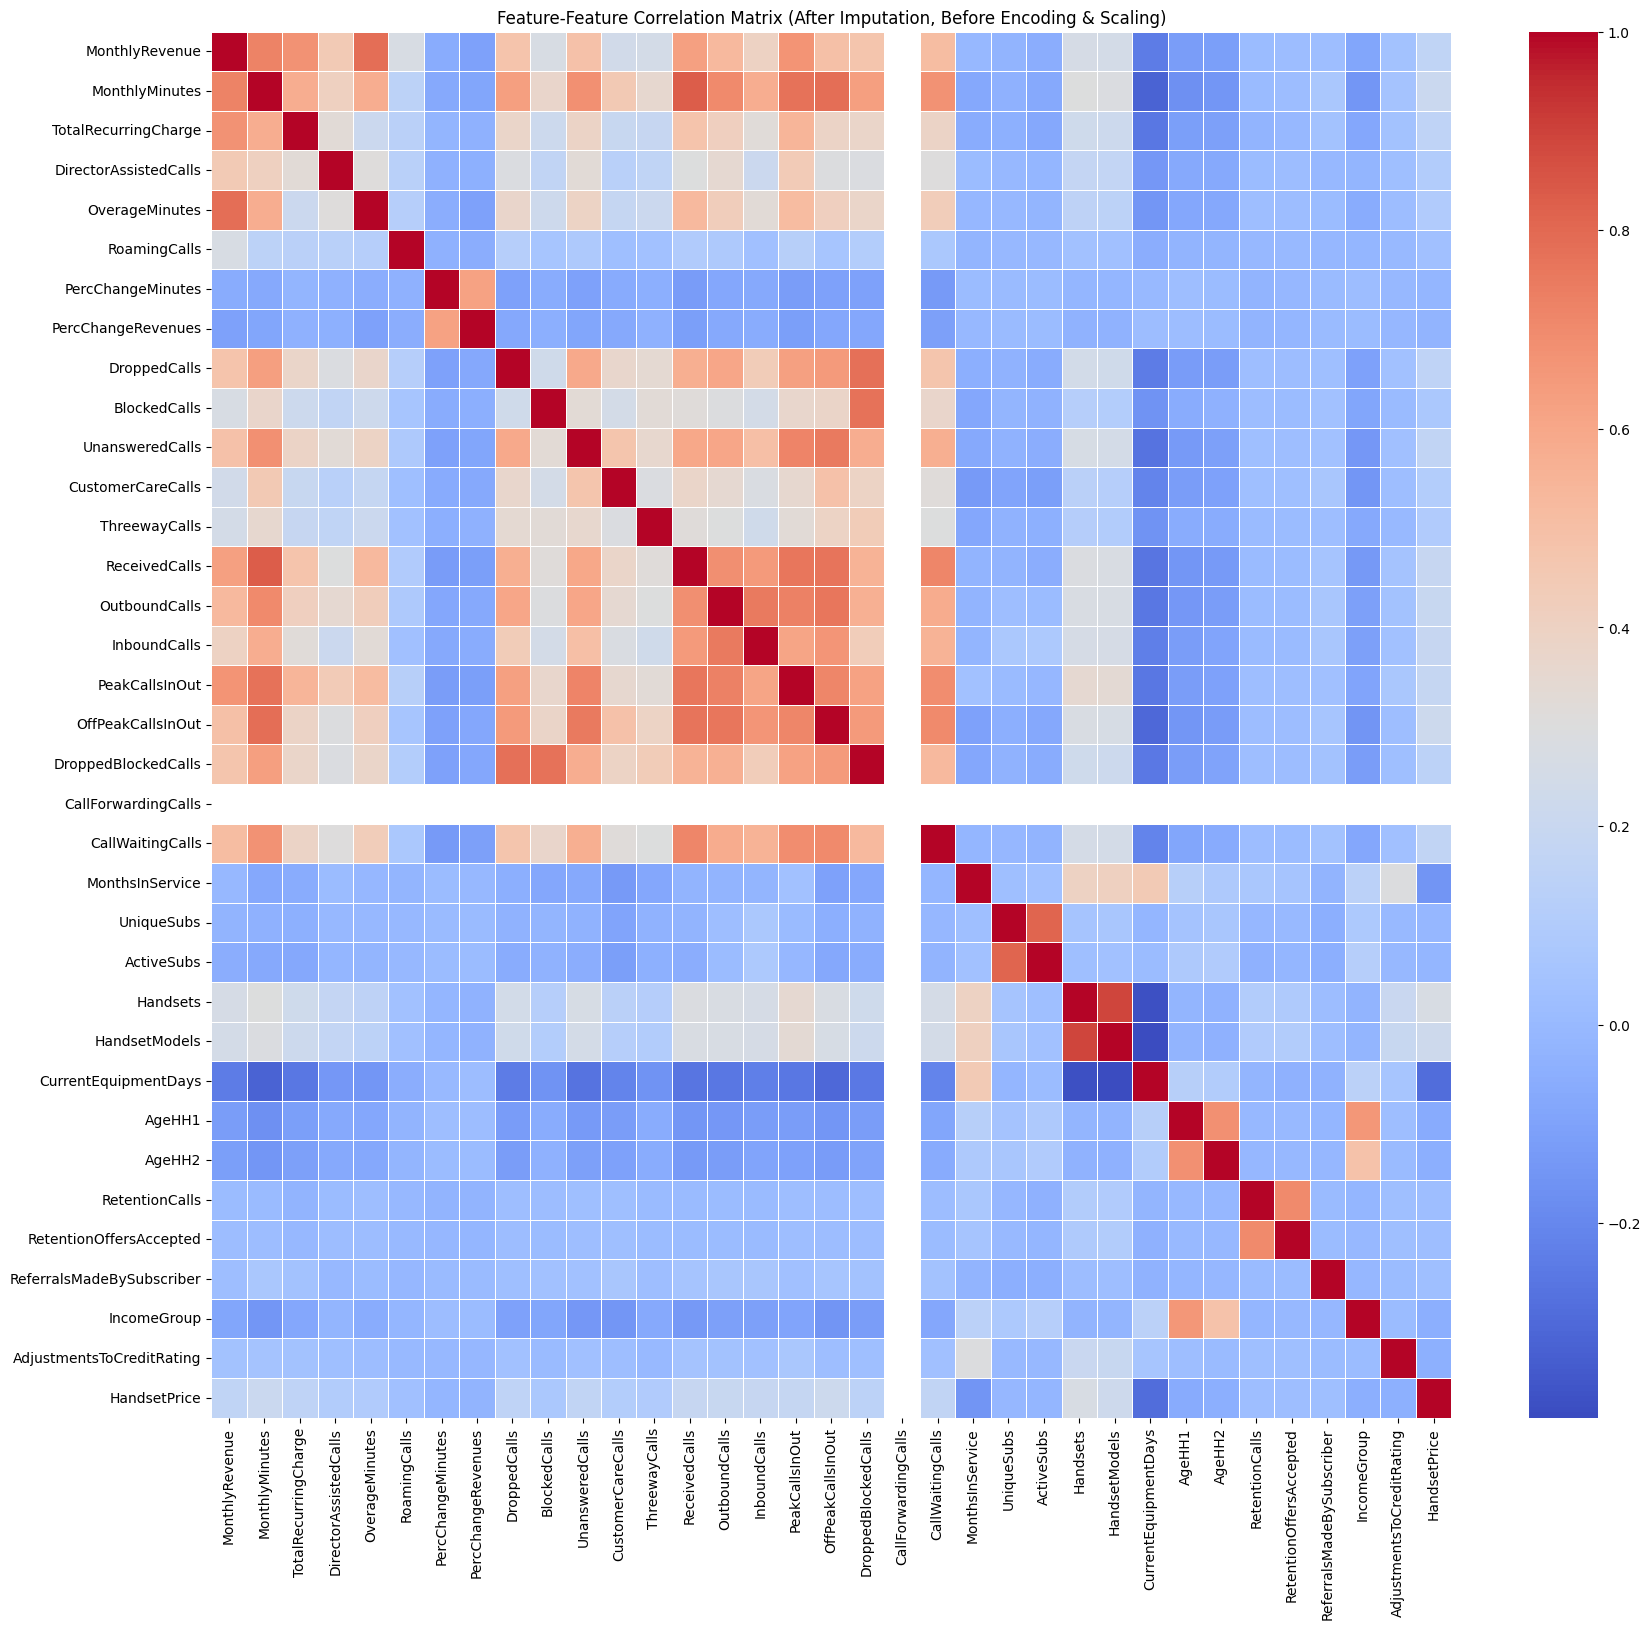

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Drop CustomerID for correlation analysis as it's an identifier, not a feature
# .corr() will automatically exclude non-numeric columns (objects)
X_train_for_corr_pre_encoding = X_features.drop(columns=['CustomerID'], errors='ignore')

# Calculate the correlation matrix for numerical features only, explicitly ignoring non-numeric columns
correlation_matrix_pre_encoding = X_train_for_corr_pre_encoding.corr(numeric_only=True)

plt.figure(figsize=(20, 18))
sns.heatmap(correlation_matrix_pre_encoding, cmap='coolwarm', annot=False, fmt=".2f", linewidths=.5)
plt.title('Feature-Feature Correlation Matrix (After Imputation, Before Encoding & Scaling)')
plt.show()

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/tmp/ipykernel_699/234609136.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_target_correlation_pre_encoding.values, y=feature_target_correlation_pre_encoding.index, palette='viridis')


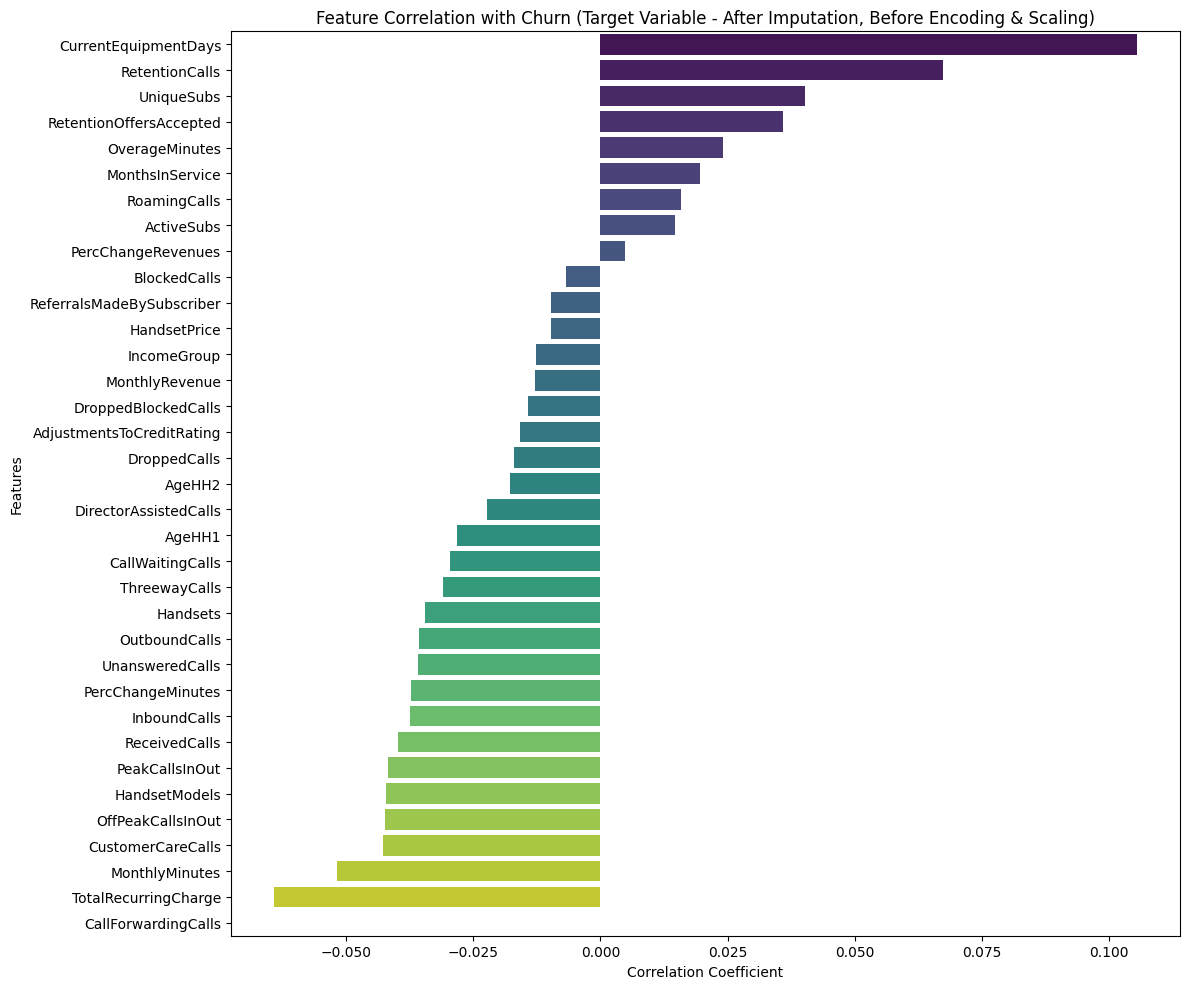

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert y_train to numeric for correlation calculation
y_train_numeric_pre_encoding = y_target.map({'Yes': 1, 'No': 0})

# Ensure y_train_numeric_pre_encoding is aligned with X_train_for_corr_pre_encoding indices
y_train_aligned_pre_encoding = y_train_numeric_pre_encoding.loc[X_train_for_corr_pre_encoding.index]

# Calculate correlations with the target variable for numerical features only
# We add numeric_only=True to prevent errors from the categorical 'ServiceArea' column
feature_target_correlation_pre_encoding = X_train_for_corr_pre_encoding.corrwith(y_train_aligned_pre_encoding, numeric_only=True).sort_values(ascending=False)

plt.figure(figsize=(12, 10))
sns.barplot(x=feature_target_correlation_pre_encoding.values, y=feature_target_correlation_pre_encoding.index, palette='viridis')
plt.title('Feature Correlation with Churn (Target Variable - After Imputation, Before Encoding & Scaling)')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

### Step 4: Categorical Encoding & Feature Scaling

This step involves transforming categorical features into numerical representations and scaling numerical features:
- **Binary Categorical Features**: Manually mapped to 0 and 1.
- **Multi-class Categorical Features**: One-Hot Encoded (dropping the first dummy to avoid multicollinearity).
- **Numerical Features**: Scaled using StandardScaler.

We use a ColumnTransformer to apply these transformations consistently to both training and holdout data, ensuring all parameters are fitted on X_train.

In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
import numpy as np
import pandas as pd
import scipy.sparse

# 1. Handle binary columns first as they are mapped in place
binary_cols = [
    'ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner',
    'BuysViaMailOrder', 'RespondsToMailOffers', 'OptOutMailings', 'NonUSTravel',
    'OwnsComputer', 'HasCreditCard', 'NewCellphoneUser', 'NotNewCellphoneUser',
    'OwnsMotorcycle', 'MadeCallToRetentionTeam'
]

for col in binary_cols:
    if col in X_features.columns:
        X_features[col] = X_features[col].map({'Yes': 1, 'No': 0, 'Unknown': 0}).fillna(0)

# Separate CustomerID before transformation
customer_id = X_features['CustomerID'].copy()

X_features_processed = X_features.drop(columns=['CustomerID']).copy()

# Identify numerical and categorical columns
numerical_features = [col for col in X_features_processed.select_dtypes(include=np.number).columns.tolist() if col in X_features_processed.columns]
categorical_features = [col for col in X_features_processed.select_dtypes(include='object').columns.tolist() if col in X_features_processed.columns]

# Conditionally create transformers
transformers = []
if numerical_features:
    transformers.append(('num', StandardScaler(), numerical_features))
if categorical_features:
    transformers.append(('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), categorical_features))

if not transformers:
    print("No features identified.")
    X_processed_transformed_df = pd.DataFrame(index=X_features.index)
else:
    preprocessor = ColumnTransformer(transformers=transformers, remainder='drop')

    # Apply transformations
    X_processed_array = preprocessor.fit_transform(X_features_processed)

    # Fix: Convert to dense array ONLY if it is a sparse matrix
    if scipy.sparse.issparse(X_processed_array):
        X_processed_array = X_processed_array.toarray()

    # Get feature names and clean up
    processed_feature_names = preprocessor.get_feature_names_out()
    cleaned_feature_names = [col.replace('num__', '').replace('cat__', '') for col in processed_feature_names]

    X_processed_transformed_df = pd.DataFrame(X_processed_array, columns=cleaned_feature_names, index=X_features.index)

# Re-attach CustomerID
X_final_features = pd.concat([customer_id.to_frame(), X_processed_transformed_df], axis=1)
y_target_processed = y_target.copy()

print("Categorical features encoded and numerical features scaled.")
print(f"Shape of X_final_features: {X_final_features.shape}")

Categorical features encoded and numerical features scaled.
Shape of X_final_features: (51047, 84)


## Step 5: Feature Correlation Analysis

Now that the data has been cleaned, encoded, and scaled, we performed a correlation analysis to understand the relationships between features and with the target variable. This will assist in making informed decisions about feature selection.

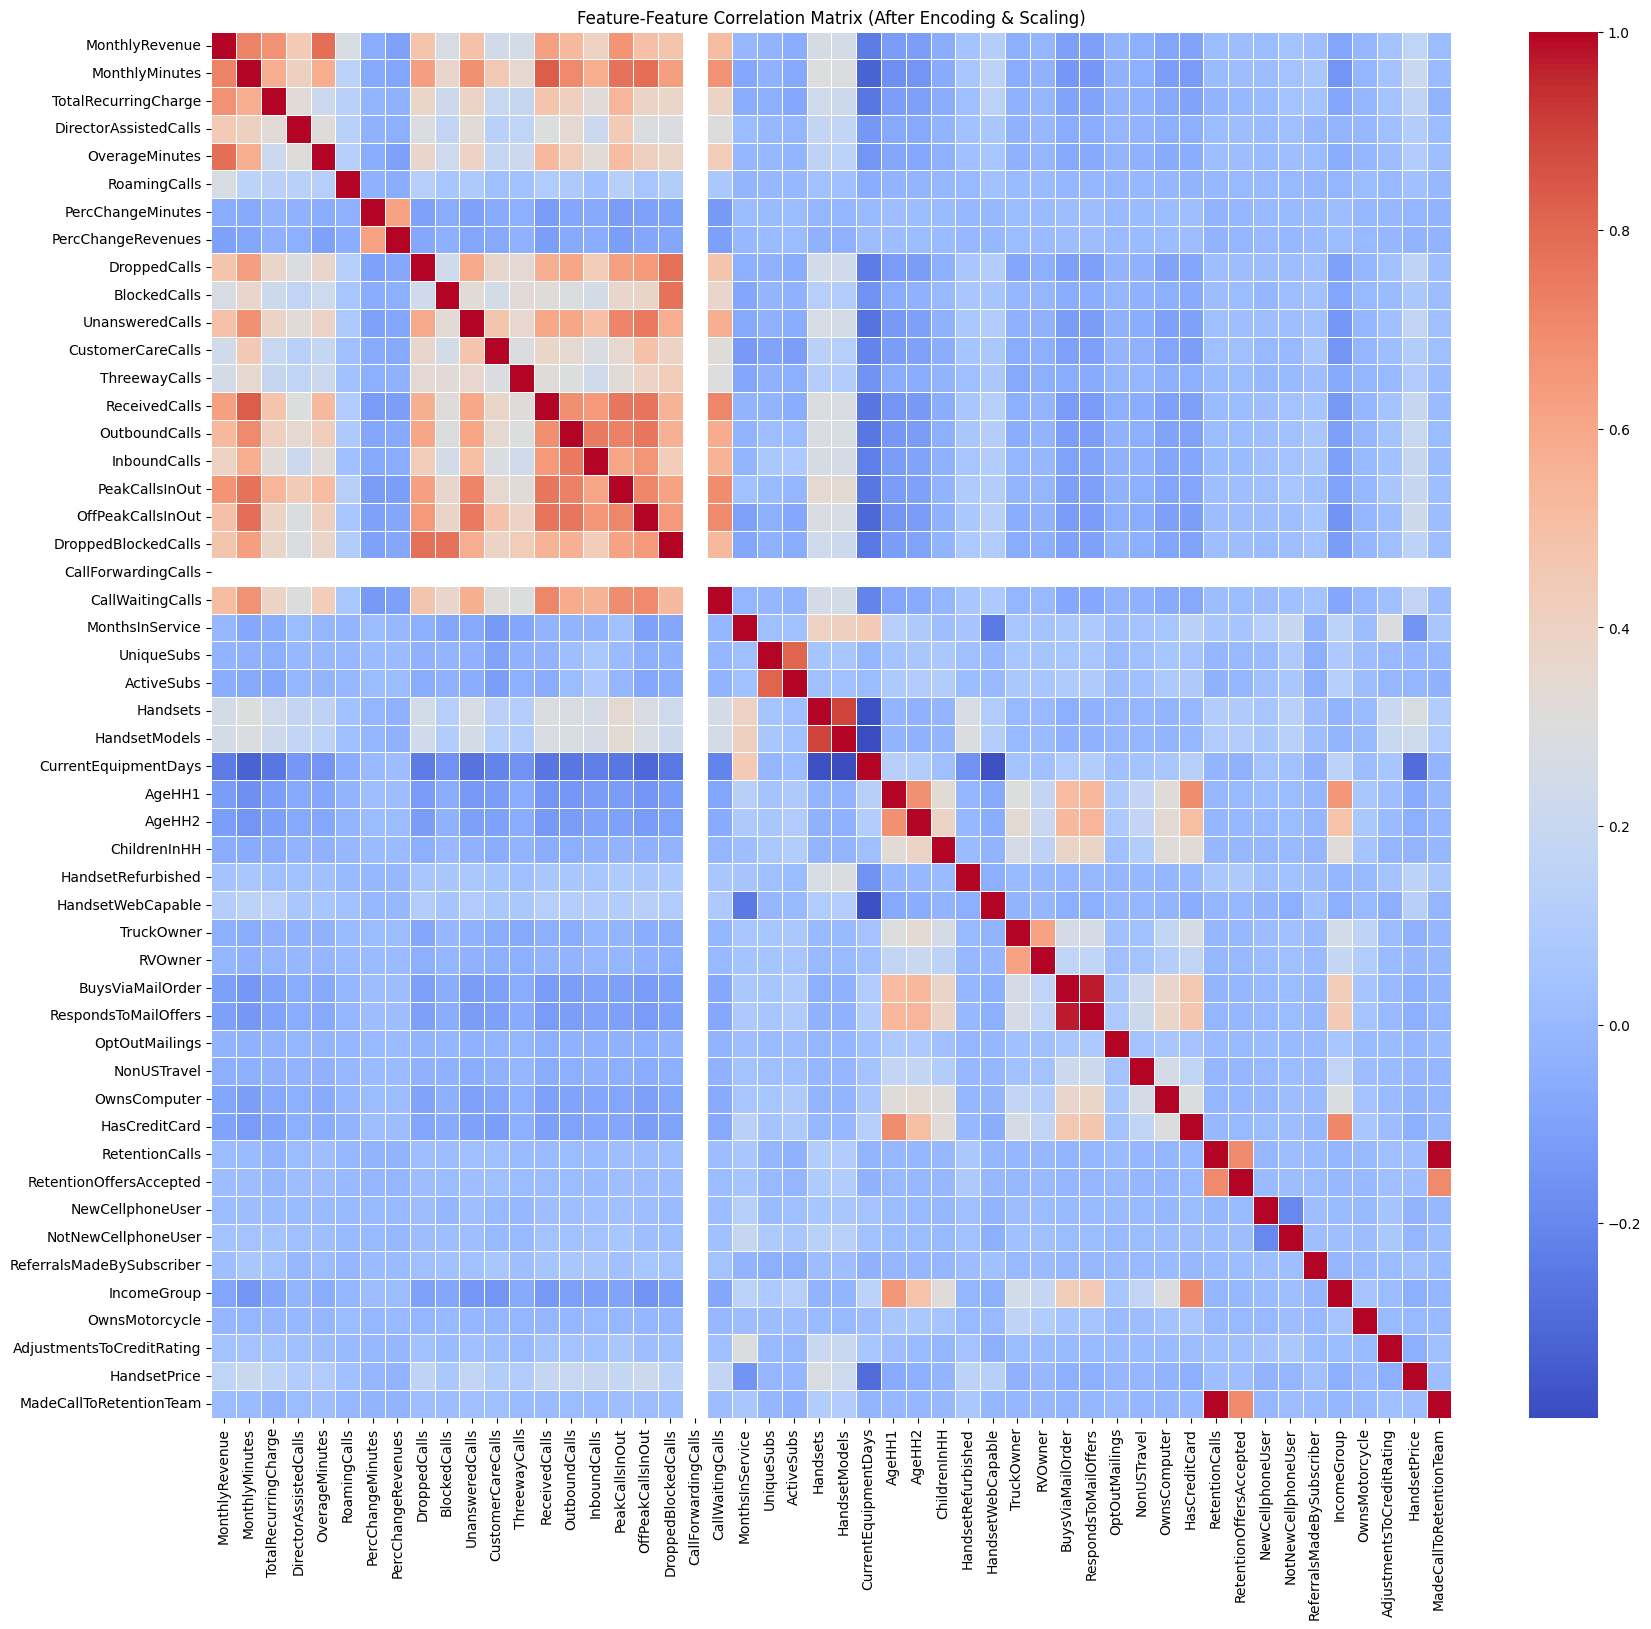

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Drop CustomerID for correlation analysis as it's an identifier, not a feature
X_train_for_corr = X_features.drop(columns=['CustomerID'], errors='ignore')

# Calculate the correlation matrix
correlation_matrix = X_train_for_corr.corr(numeric_only=True)

plt.figure(figsize=(20, 18))
sns.heatmap(correlation_matrix, cmap='coolwarm', annot=False, fmt=".2f", linewidths=.5)
plt.title('Feature-Feature Correlation Matrix (After Encoding & Scaling)')
plt.show()

### Feature-Target Correlation

Let's visualize the correlation of each feature with the target variable ('Churn'). This is a crucial step for understanding feature relevance.

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/tmp/ipykernel_699/3694800953.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_target_correlation.values, y=feature_target_correlation.index, palette='viridis')


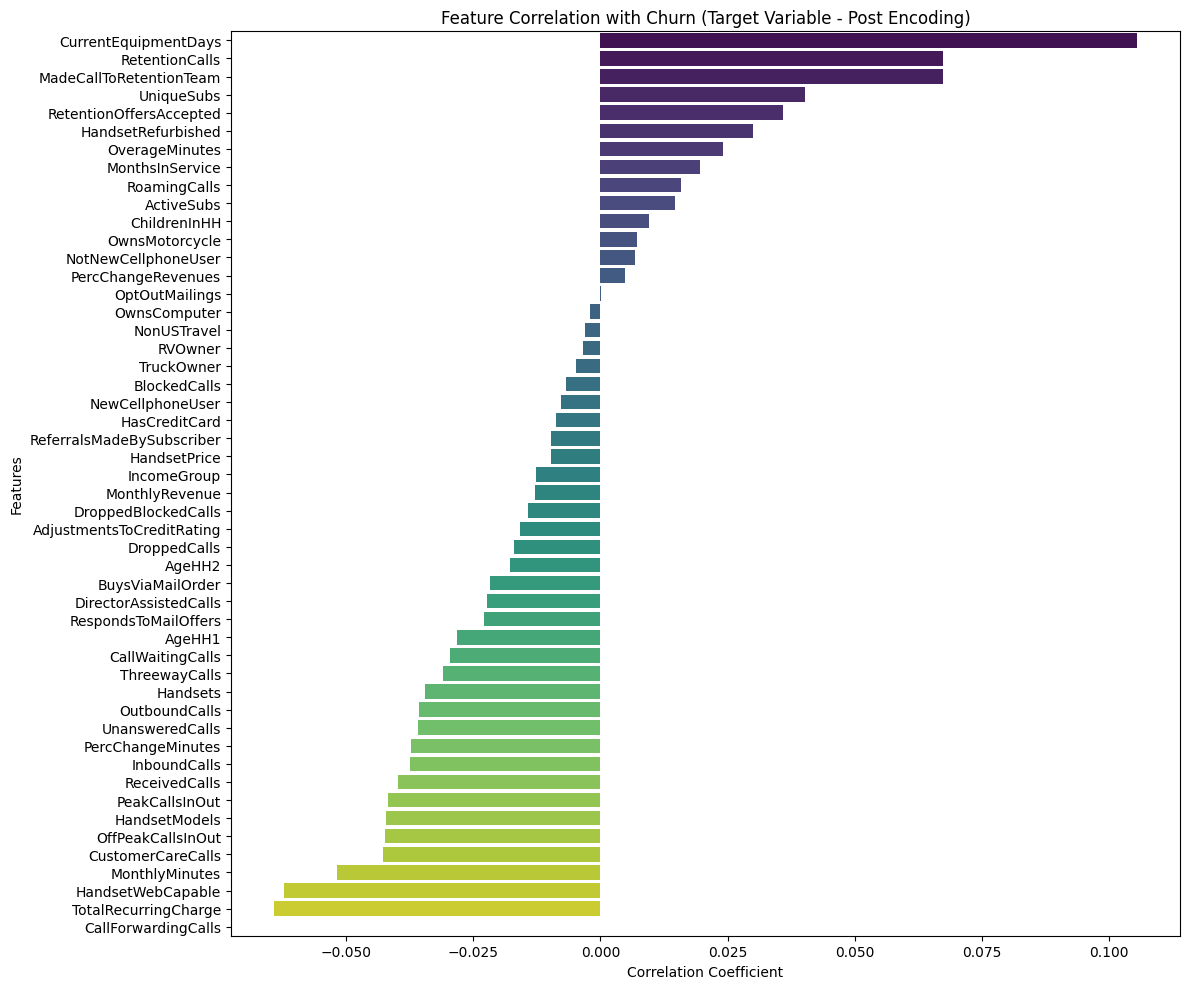

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Re-define variables needed for correlation using X_features
X_train_for_corr = X_features.drop(columns=['CustomerID'], errors='ignore')
y_train_numeric = y_target.map({'Yes': 1, 'No': 0})

# Ensure y_train_numeric is aligned with X_train_for_corr indices
y_train_aligned = y_train_numeric.loc[X_train_for_corr.index]

# Calculate correlations with the target variable
feature_target_correlation = X_train_for_corr.corrwith(y_train_aligned, numeric_only=True).sort_values(ascending=False)

plt.figure(figsize=(12, 10))
sns.barplot(x=feature_target_correlation.values, y=feature_target_correlation.index, palette='viridis')
plt.title('Feature Correlation with Churn (Target Variable - Post Encoding)')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

### Step 6: Tree-Based Top Feature Selection

We use a RandomForestClassifier to evaluate feature importance. Features with an importance score below a defined threshold (0.001) are considered less significant and are removed from the dataset.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Convert y_target_processed to numeric for RandomForestClassifier
y_target_numeric = y_target_processed.map({'Yes': 1, 'No': 0})

# Prepare X_final_features by dropping CustomerID
X_for_rf = X_final_features.drop(columns=['CustomerID'])

# Identify and remove any remaining non-numeric columns that might have slipped through
non_numeric_cols_in_rf_input = X_for_rf.select_dtypes(include=['object', 'category']).columns
if not non_numeric_cols_in_rf_input.empty:
    print(f"WARNING: Found non-numeric columns before RandomForestClassifier fit: {list(non_numeric_cols_in_rf_input)}. Dropping them.")
    X_for_rf = X_for_rf.drop(columns=non_numeric_cols_in_rf_input)

# Initialize and train a RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_for_rf, y_target_numeric)

# Get feature importances
feature_importances = pd.Series(rf.feature_importances_, index=X_for_rf.columns)

# Define a threshold for feature selection
importance_threshold = 0.001

# Identify features to keep
selected_features = feature_importances[feature_importances > importance_threshold].index.tolist()

# Always keep 'CustomerID' if it exists and was not used in feature importance
if 'CustomerID' in X_final_features.columns and 'CustomerID' not in selected_features:
    selected_features.insert(0, 'CustomerID') # Add CustomerID back to the beginning

# Filter X_final_features to keep only selected features
X_final_features_selected = X_final_features[selected_features]

print(f"Features selected based on importance threshold {importance_threshold}:")
print(selected_features)
print(f"Shape of X_final_features_selected: {X_final_features_selected.shape}")

Features selected based on importance threshold 0.001:
['CustomerID', 'MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues', 'DroppedCalls', 'BlockedCalls', 'UnansweredCalls', 'CustomerCareCalls', 'ThreewayCalls', 'ReceivedCalls', 'OutboundCalls', 'InboundCalls', 'PeakCallsInOut', 'OffPeakCallsInOut', 'DroppedBlockedCalls', 'CallWaitingCalls', 'MonthsInService', 'UniqueSubs', 'ActiveSubs', 'Handsets', 'HandsetModels', 'CurrentEquipmentDays', 'AgeHH1', 'AgeHH2', 'ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner', 'BuysViaMailOrder', 'RespondsToMailOffers', 'OptOutMailings', 'NonUSTravel', 'OwnsComputer', 'HasCreditCard', 'RetentionCalls', 'NewCellphoneUser', 'NotNewCellphoneUser', 'ReferralsMadeBySubscriber', 'IncomeGroup', 'OwnsMotorcycle', 'AdjustmentsToCreditRating', 'HandsetPrice', 'MadeCallToRetentionTeam', 'ServiceArea_APCSIL301', 'ServiceArea_

### Step 7: Final Processed Dataframes

After completing all feature engineering steps, we have the final processed dataframes, X_train_selected and *X_holdout_selected*, ready for model training and evaluation.

In [ ]:
print("X_final_features_selected head:")
display(X_final_features_selected.head())

X_final_features_selected head:


,CustomerID,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,...,PrizmCode_Rural,PrizmCode_Suburban,PrizmCode_Town,Occupation_Crafts,Occupation_Other,Occupation_Professional,Occupation_Retired,Occupation_Self,MaritalStatus_Unknown,MaritalStatus_Yes
0,3000002,-0.884634,-0.601461,-1.109034,-0.357810,-0.5035,-0.303087,-0.589870,-0.526685,-0.660851,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,3000010,-1.067499,-1.020172,-1.335769,-0.510497,-0.5035,-0.303087,0.044720,0.061532,-0.712374,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,3000014,-0.519426,-1.024179,-0.383480,-0.510497,-0.5035,-0.303087,0.053015,0.061532,-0.751016,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3,3000022,0.635676,1.588257,1.294362,0.246832,-0.5035,-0.303087,0.712491,0.312298,4.697546,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,3000026,-1.063586,-1.040206,-1.335769,-0.510497,-0.5035,-0.303087,0.061310,0.055340,-0.751016,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


### Step 8: Export Cleaned Datasets

Finally, we export the `X_train_selected` and `X_holdout_selected` DataFrames to CSV files. These files contain the preprocessed features, ready for model training and evaluation.

In [ ]:
output_path = '/content/drive/MyDrive/437/project_dataset/'

X_final_features_selected.to_csv(f'{output_path}X_processed.csv', index=False)
y_target_processed.to_csv(f'{output_path}y_processed.csv', index=False)

print(f"Cleaned X data saved to: {output_path}X_processed.csv")
print(f"Cleaned y data saved to: {output_path}y_processed.csv")

Cleaned X data saved to: /content/drive/MyDrive/437/project_dataset/X_processed.csv
Cleaned y data saved to: /content/drive/MyDrive/437/project_dataset/y_processed.csv




# ==============================================================================

